<a href="https://colab.research.google.com/github/pendulumswings/pendulumswings.github.io/blob/main/scripts/chapter7/pendulum_train_trajectories.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Pendulum Trajectories in a Horizontally Accelerating Train.

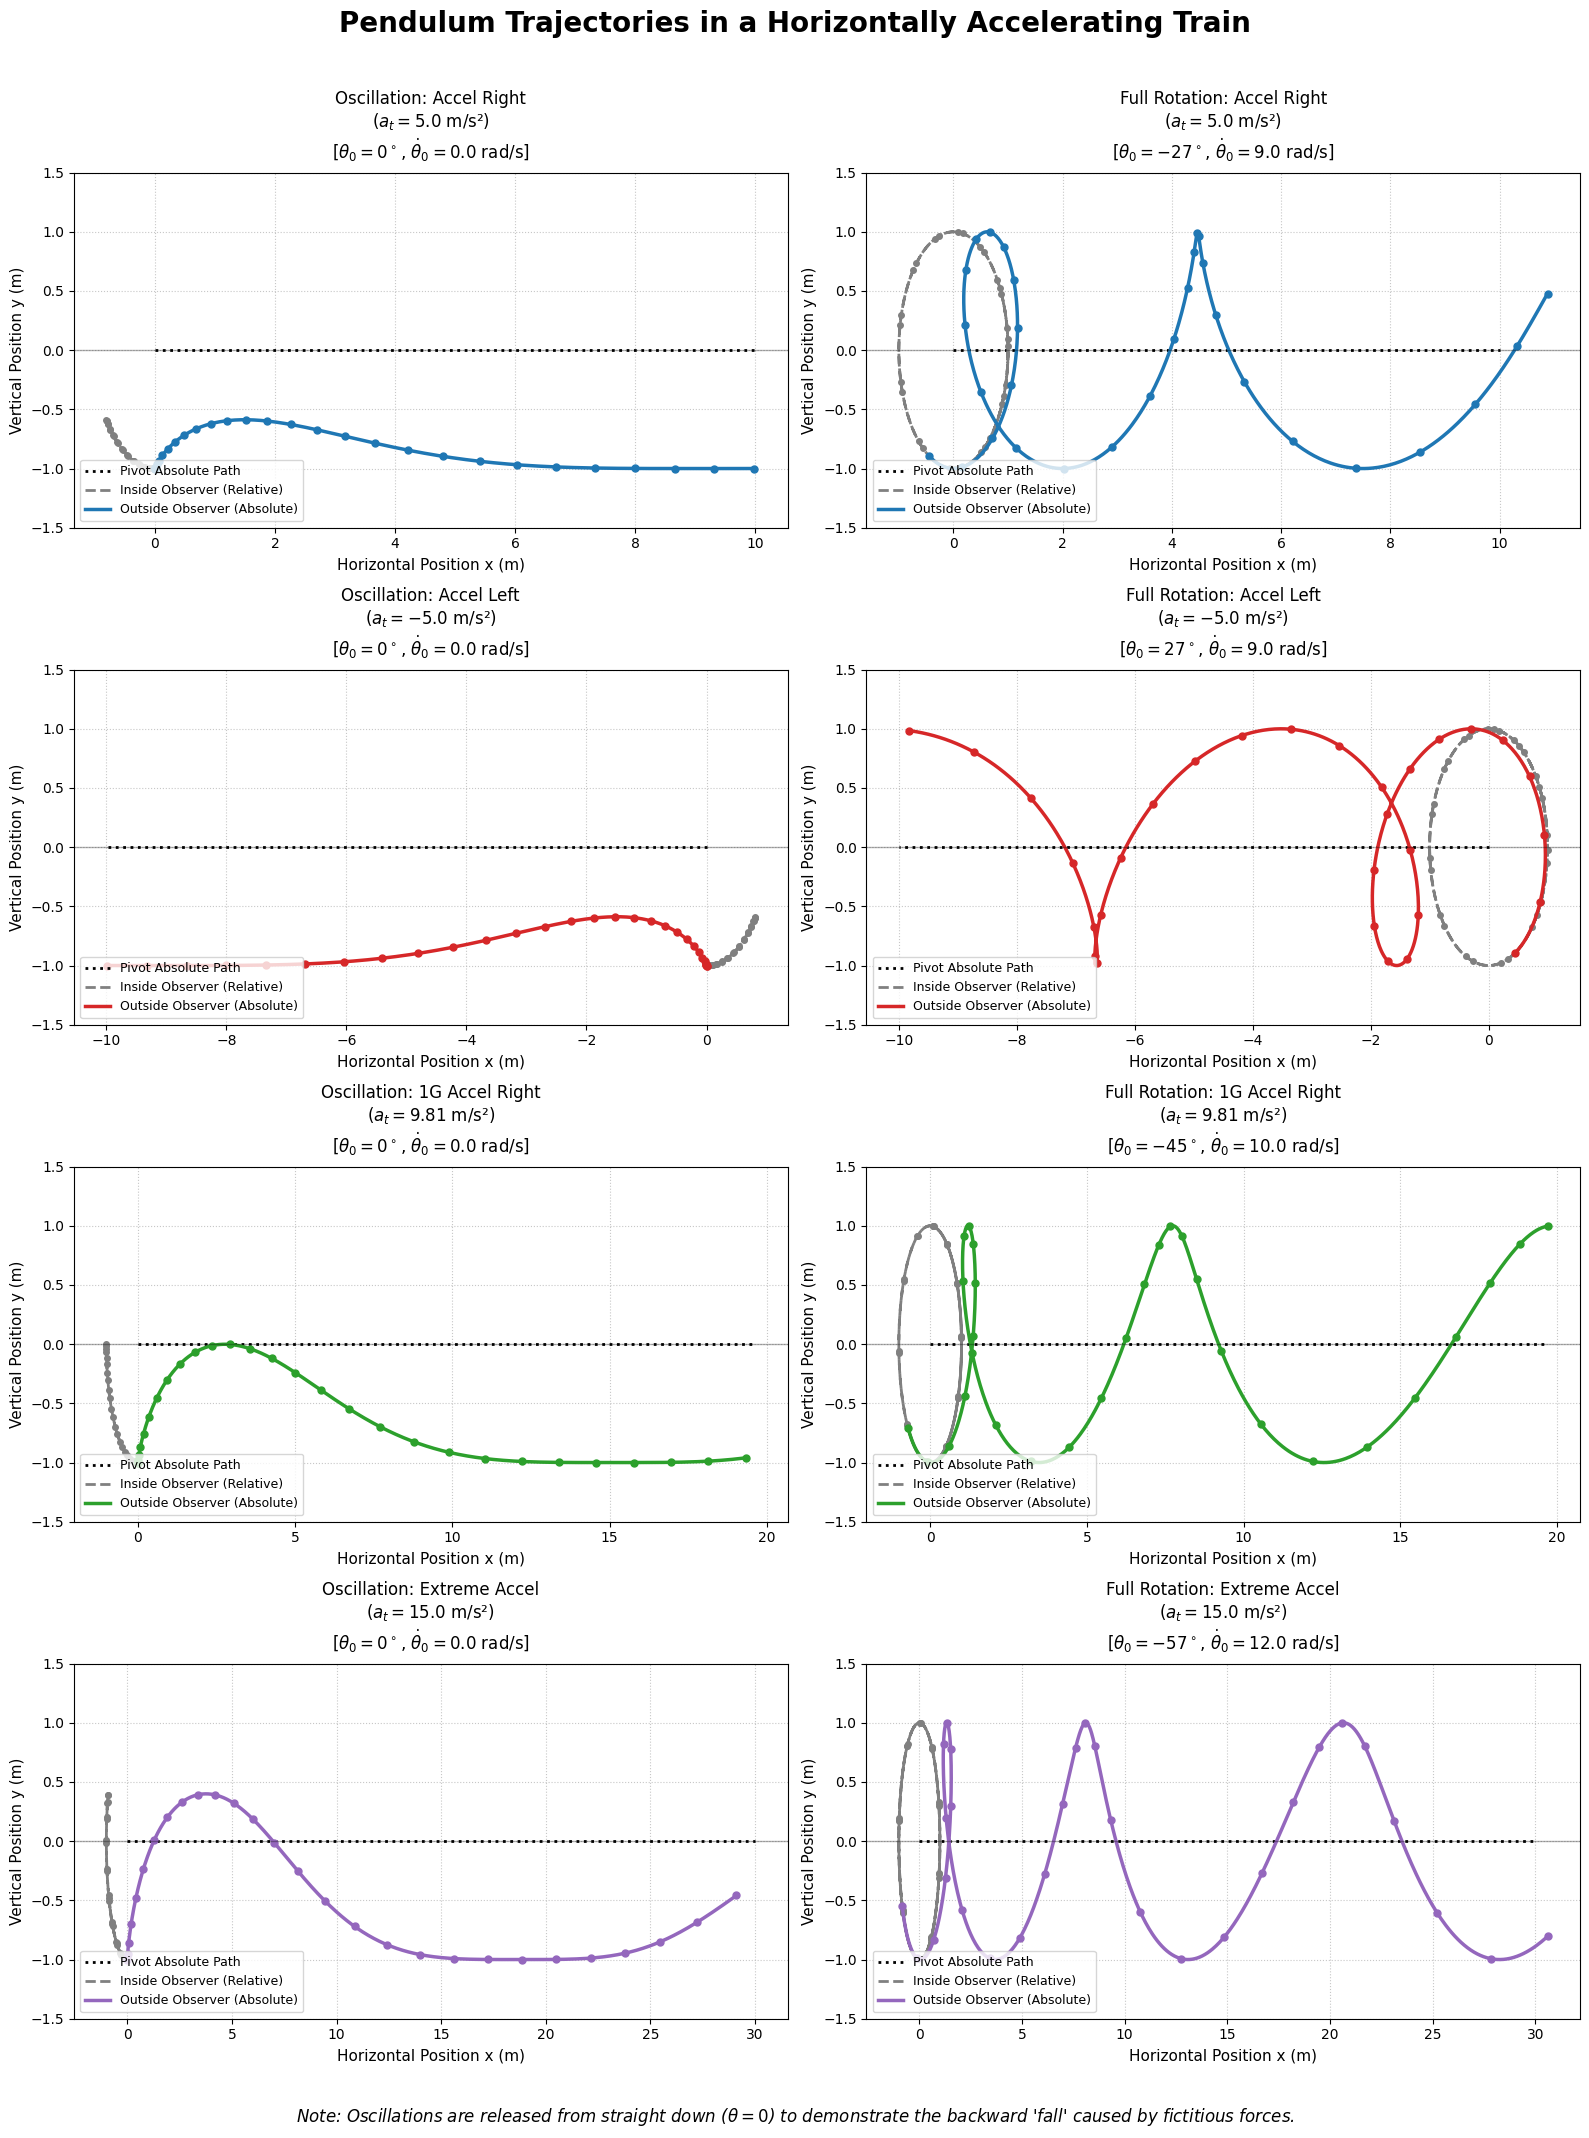

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# Physics Constants
g = 9.81        # Acceleration due to gravity (m/s^2)
l = 1.0         # Length of the pendulum string (m)

# Time span for the simulation
t_max = 2.0
t_span = (0, t_max)
t_eval = np.linspace(t_span[0], t_span[1], 1000)
t_markers = np.linspace(t_span[0], t_span[1], 30) # Dots for visualizing time flow

# Helper function to find the tilted equilibrium angle
def get_th_eq(ax):
    return np.arctan2(-ax, g)

# Scenarios: (Title, Kinematic Accel a_x in m/s^2, Color, Initial Theta, Initial Omega)
# Oscillation: Released from straight down (theta=0) to show it "falling" backward.
# Rotation: Launched from its tilted equilibrium position with high velocity.
scenarios = [
    # Row 1: Normal Acceleration Right
    ("Oscillation: Accel Right\n($a_t = 5.0$ m/s²)", 5.0, "#1f77b4", 0.0, 0.0),
    ("Full Rotation: Accel Right\n($a_t = 5.0$ m/s²)", 5.0, "#1f77b4", get_th_eq(5.0), 9.0),

    # Row 2: Normal Acceleration Left
    ("Oscillation: Accel Left\n($a_t = -5.0$ m/s²)", -5.0, "#d62728", 0.0, 0.0),
    ("Full Rotation: Accel Left\n($a_t = -5.0$ m/s²)", -5.0, "#d62728", get_th_eq(-5.0), 9.0),

    # Row 3: 1G Acceleration Right (45 degree tilt)
    ("Oscillation: 1G Accel Right\n($a_t = 9.81$ m/s²)", 9.81, "#2ca02c", 0.0, 0.0),
    ("Full Rotation: 1G Accel Right\n($a_t = 9.81$ m/s²)", 9.81, "#2ca02c", get_th_eq(9.81), 10.0),

    # Row 4: Extreme Acceleration Right
    ("Oscillation: Extreme Accel\n($a_t = 15.0$ m/s²)", 15.0, "#9467bd", 0.0, 0.0),
    ("Full Rotation: Extreme Accel\n($a_t = 15.0$ m/s²)", 15.0, "#9467bd", get_th_eq(15.0), 12.0)
]

fig, axs = plt.subplots(4, 2, figsize=(16, 22))
fig.suptitle("Pendulum Trajectories in a Horizontally Accelerating Train", fontsize=20, fontweight='bold', y=0.97)
axs = axs.flatten()

for idx, (title, ax_accel, color, th0, om0) in enumerate(scenarios):
    ax = axs[idx]

    # 1. Define the Ordinary Differential Equation (ODE) for the train pendulum
    # The equation of motion is: theta_ddot = - (g/l)*sin(theta) - (a_x/l)*cos(theta)
    def train_ode(t, state, current_ax):
        theta, omega = state
        dtheta = omega
        domega = -(g / l) * np.sin(theta) - (current_ax / l) * np.cos(theta)
        return [dtheta, domega]

    # 2. Solve the ODE numerically
    sol = solve_ivp(train_ode, t_span, [th0, om0], t_eval=t_eval, method='RK45', args=(ax_accel,))
    theta_t = sol.y[0]

    # Solve specifically for the marker points to overlay time-dots
    sol_markers = solve_ivp(train_ode, t_span, [th0, om0], t_eval=t_markers, method='RK45', args=(ax_accel,))
    theta_m = sol_markers.y[0]

    # 3. Calculate Non-Inertial (Inside Observer) Trajectory
    # Origin is fixed at the train's ceiling pivot (0,0)
    x_rel = l * np.sin(theta_t)
    y_rel = -l * np.cos(theta_t)

    x_rel_m = l * np.sin(theta_m)
    y_rel_m = -l * np.cos(theta_m)

    # 4. Calculate Inertial (Outside Observer) Trajectory
    # Pivot moves horizontally according to x = 0.5 * a_x * t^2
    x_pivot = 0.5 * ax_accel * t_eval**2
    y_abs = y_rel                             # Y-position is the same in both frames
    x_abs = x_pivot + x_rel                   # X-position has the train's macro motion added

    x_pivot_m = 0.5 * ax_accel * t_markers**2
    y_abs_m = y_rel_m
    x_abs_m = x_pivot_m + x_rel_m

    # 5. Plotting the Trajectories
    # Plot the pivot's absolute path (the train ceiling)
    ax.plot(x_pivot, np.zeros_like(t_eval), label="Pivot Absolute Path", color='black', linestyle='dotted', linewidth=2)

    # Plot the Non-Inertial (Inside) path
    ax.plot(x_rel, y_rel, label="Inside Observer (Relative)", color='gray', linestyle='dashed', linewidth=2)
    ax.plot(x_rel_m, y_rel_m, 'o', color='gray', markersize=4) # Time markers

    # Plot the Inertial (Outside) path
    ax.plot(x_abs, y_abs, label="Outside Observer (Absolute)", color=color, linewidth=2.5)
    ax.plot(x_abs_m, y_abs_m, 'o', color=color, markersize=5) # Time markers

    # Dynamically add the initial starting conditions to the plot title
    th0_deg = int(np.round(np.degrees(th0)))
    detailed_title = f"{title}\n[$\\theta_0 = {th0_deg}^\\circ$, $\\dot{{\\theta}}_0 = {om0}$ rad/s]"

    ax.set_title(detailed_title, fontsize=12, pad=10)
    ax.set_xlabel("Horizontal Position x (m)", fontsize=11)
    ax.set_ylabel("Vertical Position y (m)", fontsize=11)

    # Add a horizontal line at y=0 representing the train ceiling
    ax.axhline(0, color='black', linewidth=1, alpha=0.3)

    # Lock the Y-axis to strictly show the string bounds, but let X auto-scale for macro motion
    ax.set_ylim(-1.5, 1.5)
    ax.grid(True, linestyle=':', alpha=0.7)

    # Legend placement
    ax.legend(loc='lower left', fontsize=9)

plt.figtext(0.5, 0.01, "Note: Oscillations are released from straight down ($\\theta=0$) to demonstrate the backward 'fall' caused by fictitious forces.",
            ha="center", fontsize=12, style='italic')

plt.tight_layout(rect=[0, 0.03, 1, 0.96])
plt.show()